# Informe de laboratorio: análisis exploratorio de deserción universitaria
## 1. Portada y contexto
**Institución:** Corporación Universitaria Minuto de Dios – UNIMINUTO  
**Programa:** Ingeniería de Sistemas · **Asignatura:** Minería de Datos  
**Docente:** Esteban Ernesto Morales Castro  
**Integrantes:** Jonathan Díaz Salgado y Diego Alberto Ñanguma Briñez  
**Fecha de elaboración:** 18 de octubre de 2026

### Pregunta del proyecto
¿Qué características académicas y de contexto pueden relacionarse con el abandono universitario y orientar un futuro análisis de riesgo?

### Objetivo de este análisis
Describir las variables académicas disponibles, verificar su calidad y explorar asociaciones que permitan formular recomendaciones de revisión y acompañamiento. En este avance no se entrena un predictor.

### Datos y alcance
Se utiliza StudentDropoutDataset, publicado en [Zenodo](https://doi.org/10.5281/zenodo.17239943), licencia CC BY 4.0. Los datos pertenecen a una universidad española, no a estudiantes de UNIMINUTO. La base SQLite fue facilitada por Jonathan.

Una fila original representa una matrícula en una asignatura. Para este EDA se propone como unidad **estudiante-programa-año** y se usa la mediana de las variables numéricas de las matrículas de cada grupo. Una persona puede aparecer en varios años o programas; no se asume independencia estadística.

El cuaderno sigue las seis secciones del informe: contexto, calidad, univariado, relaciones, hallazgos y anexos. Contiene **cuatro gráficas univariadas y tres de relaciones**, todas interpretadas.

**Pendiente de interpretación:** los estados A/B no tienen un mapa semántico en los archivos recibidos. Se comparan como códigos sin llamar a ninguno “desertor”. Deben confirmarse etiqueta, horizonte y definiciones académicas para completar la interpretación del proyecto.

### Carga y herramientas
Guardar este archivo junto a `desercion_estudiantes.db`. Requiere pandas, numpy y matplotlib. Si falta una librería, usar en una celda temporal `%pip install pandas matplotlib` y reiniciar el kernel.

La conexión es de solo lectura. La carpeta `resultados_entrega` contendrá las siete figuras, tablas, CSV analítico, diccionario y bitácora. La base original no se modifica.

Se conservan los datos originales porque la tabla preparada rellenó todo el rendimiento ausente de 2018 con un único valor. Esta decisión de limpieza se documenta y se revisa antes de utilizarla como evidencia.

In [1]:
from pathlib import Path
import sqlite3
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUTA_BD = Path('desercion_estudiantes.db').resolve()
if not RUTA_BD.is_file():
    RUTA_BD = Path('/Users/usuario/Desktop/entrega_mineria/desercion_estudiantes.db')
if not RUTA_BD.is_file():
    raise FileNotFoundError('Coloca la base junto al notebook o ajusta RUTA_BD.')
SALIDA = Path('resultados_entrega')
SALIDA.mkdir(exist_ok=True)
variables = ['rendimiento_total', 'cred_sup', 'cred_mat_total', 'rend_total_ultimo']
claves = ['dni_hash', 'tit_hash', 'cohorte']
categorias = ['abandono_hash', 'dedicacion']
columnas = ', '.join(claves + ['asi_hash'] + categorias + variables)
with sqlite3.connect(RUTA_BD.resolve().as_uri() + '?mode=ro', uri=True) as conexion:
    originales = pd.read_sql_query('SELECT ' + columnas + ' FROM estudiantes_consolidados', conexion)
    rendimiento_preparado = pd.read_sql_query(
        'SELECT cohorte, rendimiento_total FROM estudiantes_limpios', conexion)

def mostrar_figura(fig, nombre):
    fig.tight_layout()
    fig.savefig(SALIDA / nombre, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

print('Matrículas originales:', len(originales))
print('Personas distintas:', originales['dni_hash'].nunique())
print('Base abierta en solo lectura.')

Matrículas originales: 464739
Personas distintas: 39364
Base abierta en solo lectura.


## 2. Calidad de datos y decisiones
Se revisan nulos, repeticiones y extremos antes de interpretar resultados. Una tabla llamada “limpia” no garantiza que cada tratamiento sea adecuado.

### 2.1 Faltantes y preparación recibida
Se cuantifica el rendimiento por año antes y después de la preparación. La ausencia de todo un año no se trata como si fueran unos pocos faltantes aislados. Los faltantes de las variables analizadas se conservan y se usan valores disponibles en cada cálculo; no se rellenan automáticamente con cero ni con una mediana global.

In [2]:
calidad_anio = originales.groupby('cohorte')['rendimiento_total'].agg(filas='size', observados='count')
calidad_anio['faltantes'] = calidad_anio['filas'] - calidad_anio['observados']
calidad_anio = calidad_anio.join(rendimiento_preparado.groupby('cohorte')['rendimiento_total'].agg(
    minimo_preparado='min', maximo_preparado='max', valores_distintos_preparados='nunique'))
display(calidad_anio)
calidad_anio.to_csv(SALIDA / 'calidad_rendimiento_por_anio.csv')
display(originales[variables + categorias].isna().sum().rename('faltantes_originales'))
display(Markdown(f'**Resultado y decisión:** en 2018 faltan '
                 f'**{int(calidad_anio.loc[2018, "faltantes"]):,}** rendimientos de '
                 f'**{int(calidad_anio.loc[2018, "filas"]):,}** matrículas. '
                 f'La tabla preparada tiene un único valor en ese año: '
                 f'**{calidad_anio.loc[2018, "minimo_preparado"]:.2f}**. '
                 'No se considera una medición real. Para describir rendimiento se conservan los valores originales disponibles.'))

,filas,observados,faltantes,minimo_preparado,maximo_preparado,valores_distintos_preparados
cohorte,,,,,,
2018,152446,0,152446,93.020,93.02,1
2021,153120,144470,8650,60.225,100.00,381
2022,159173,150354,8819,60.225,100.00,400


rendimiento_total    169915
cred_sup                  0
cred_mat_total            0
rend_total_ultimo    165500
abandono_hash             0
dedicacion                0
Name: faltantes_originales, dtype: int64

**Resultado y decisión:** en 2018 faltan **152,446** rendimientos de **152,446** matrículas. La tabla preparada tiene un único valor en ese año: **93.02**. No se considera una medición real. Para describir rendimiento se conservan los valores originales disponibles.

### 2.2 Duplicados y construcción de la vista analítica
Se comprueban **filas idénticas de toda la tabla original**, no solo identificadores repetidos. La comprobación recorre las filas por bloques para no cargar todas las columnas a la vez. Utiliza un hash para localizar posibles repeticiones y compara los valores completos antes de confirmar un duplicado; el hash no determina por sí solo el resultado.

Después se normalizan las categorías preservando ausencias y se agrupa por estudiante-programa-año. Si un grupo tiene códigos de estado o dedicación contradictorios se marca `CONFLICTO`; no se escoge uno al azar. La mediana numérica resume las matrículas, no demuestra que todas sus mediciones sean idénticas.

Esta comprobación puede tardar varios minutos por el tamaño de la base.

In [3]:
vistos = {}
duplicados_originales = 0
leidas = 0
with sqlite3.connect(RUTA_BD.resolve().as_uri() + '?mode=ro', uri=True) as conexion:
    cursor = conexion.execute('SELECT rowid, * FROM estudiantes_consolidados')
    while True:
        bloque = cursor.fetchmany(5000)
        if not bloque:
            break
        for fila in bloque:
            rowid, valores = fila[0], tuple(fila[1:])
            huella = hashlib.sha256(repr(valores).encode('utf-8')).digest()
            if huella not in vistos:
                vistos[huella] = [rowid]
            else:
                iguales = False
                for previo in vistos[huella]:
                    referencia = conexion.execute('SELECT * FROM estudiantes_consolidados WHERE rowid=?', (previo,)).fetchone()
                    if tuple(referencia) == valores:
                        iguales = True
                        break
                if iguales:
                    duplicados_originales += 1
                else:
                    vistos[huella].append(rowid)
        leidas += len(bloque)
        if leidas % 100000 == 0:
            print('Filas verificadas:', leidas)
del vistos
print('Filas originales examinadas:', leidas)
print('Duplicados exactos confirmados:', duplicados_originales)

base = originales.copy()
# La agregación resume matrículas; no reconstruye el detalle de cada asignatura.
for col in claves[:2] + ['asi_hash'] + categorias:
    base[col] = base[col].astype('string').str.strip().str.upper()
    base[col] = base[col].replace({'': pd.NA, 'NAN': pd.NA, 'NONE': pd.NA, 'NULL': pd.NA, '<NA>': pd.NA})
for col in variables:
    base[col] = pd.to_numeric(base[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
sin_clave = base[claves].isna().any(axis=1)
base_valida = base.loc[~sin_clave].copy()

def categoria_consistente(s):
    valores = s.dropna().unique()
    return valores[0] if len(valores) == 1 else ('CONFLICTO' if len(valores) > 1 else pd.NA)

grupos = base_valida.groupby(claves, sort=True)
datos = grupos[variables].median()
for col in categorias:
    datos[col] = grupos[col].agg(categoria_consistente)
datos['n_matriculas'] = grupos.size()
datos = datos.reset_index()
assert not datos.duplicated(claves).any()
print('Excluidas por clave incompleta:', int(sin_clave.sum()))
print('Unidades estudiante-programa-año:', len(datos))
print('Duplicados de la clave analítica:', int(datos.duplicated(claves).sum()))
print('Conflictos de estado:', int(datos['abandono_hash'].eq('CONFLICTO').sum()))
print('Conflictos de dedicación:', int(datos['dedicacion'].eq('CONFLICTO').sum()))
display(datos[variables + categorias].isna().sum().rename('faltantes_vista_analitica'))
if duplicados_originales:
    display(Markdown('**Pendiente de calidad:** se detectaron repeticiones exactas. Antes de aceptar la vista analítica, revisar su efecto sobre la mediana y decidir una deduplicación documentada.'))
else:
    display(Markdown('**Decisión:** no se eliminaron filas por duplicación exacta porque no se encontraron. La repetición de una persona en distintas materias no se trata como error.'))

Filas verificadas: 100000


Filas verificadas: 200000


Filas verificadas: 300000


Filas verificadas: 400000


Filas originales examinadas: 464739
Duplicados exactos confirmados: 0


Excluidas por clave incompleta: 0
Unidades estudiante-programa-año: 60924
Duplicados de la clave analítica: 0
Conflictos de estado: 0
Conflictos de dedicación: 0


rendimiento_total    22573
cred_sup                 0
cred_mat_total           0
rend_total_ultimo    17154
abandono_hash            0
dedicacion               0
Name: faltantes_vista_analitica, dtype: int64

**Decisión:** no se eliminaron filas por duplicación exacta porque no se encontraron. La repetición de una persona en distintas materias no se trata como error.

### 2.3 Valores extremos y bitácora
La regla IQR señala valores fuera de Q1−1,5·IQR y Q3+1,5·IQR. Sirve para revisar extremos, no para declararlos errores. Se conservan las mediciones disponibles mientras se confirman rangos y periodos académicos.

La bitácora registra el alcance y las decisiones. Los rangos observados no se presentan como límites oficiales.

In [4]:
extremos = []
for col in variables:
    s = datos[col].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    extremos.append({'variable': col, 'n_observados': len(s), 'q1': q1, 'q3': q3,
                     'limite_inferior': inferior, 'limite_superior': superior,
                     'n_extremos': int(((s < inferior) | (s > superior)).sum())})
extremos = pd.DataFrame(extremos).set_index('variable')
display(extremos.round(2))
extremos.to_csv(SALIDA / 'extremos_iqr.csv')
bitacora = pd.DataFrame([
    {'Aspecto': 'Duplicados', 'Resultado': str(duplicados_originales) + ' exactos en la tabla original', 'Decisión': 'No borrar matrículas solo por repetir persona'},
    {'Aspecto': 'Faltantes', 'Resultado': 'Rendimiento ausente en todo 2018', 'Decisión': 'Conservar ausencias; cálculos con valores disponibles'},
    {'Aspecto': 'Texto', 'Resultado': 'Categorías normalizadas sin convertir nulos a palabras', 'Decisión': 'Limpiar espacios/mayúsculas; conflictos explícitos'},
    {'Aspecto': 'Unidad', 'Resultado': str(len(datos)) + ' unidades estudiante-programa-año', 'Decisión': 'Mediana numérica; categoría consistente por grupo'},
    {'Aspecto': 'Extremos', 'Resultado': 'Cuantificados por IQR en cada variable', 'Decisión': 'Conservar y revisar por contexto'}])
display(bitacora)
bitacora.to_csv(SALIDA / 'bitacora.csv', index=False)

,n_observados,q1,q3,limite_inferior,limite_superior,n_extremos
variable,,,,,,
rendimiento_total,38351,65.71,100.0,14.27,151.44,3640
cred_sup,60924,24.00,60.0,-30.00,114.00,552
cred_mat_total,60924,46.50,60.0,26.25,80.25,8410
rend_total_ultimo,43770,70.00,100.0,25.00,145.00,3141


,Aspecto,Resultado,Decisión
0,Duplicados,0 exactos en la tabla original,No borrar matrículas solo por repetir persona
1,Faltantes,Rendimiento ausente en todo 2018,Conservar ausencias; cálculos con valores disp...
2,Texto,Categorías normalizadas sin convertir nulos a ...,Limpiar espacios/mayúsculas; conflictos explíc...
3,Unidad,60924 unidades estudiante-programa-año,Mediana numérica; categoría consistente por grupo
4,Extremos,Cuantificados por IQR en cada variable,Conservar y revisar por contexto


## 3. Análisis univariado
Se estudia una variable a la vez. Primero se presenta la tabla descriptiva y después **cuatro figuras separadas e interpretadas**: histograma y boxplot de rendimiento, e histograma y boxplot de créditos.

La media y la mediana describen el centro, los cuartiles y la desviación la dispersión, y la asimetría la forma. Con asimetría marcada conviene comunicar la mediana acompañada de cuartiles.

In [5]:
resumen = datos[variables].describe().T
resumen['faltantes'] = datos[variables].isna().sum()
resumen['asimetria'] = datos[variables].skew()
resumen['IQR'] = datos[variables].quantile(.75) - datos[variables].quantile(.25)
display(resumen.round(2))
resumen.to_csv(SALIDA / 'resumen_estadistico.csv')

,count,mean,std,min,25%,50%,75%,max,faltantes,asimetria,IQR
rendimiento_total,38351.0,77.52,31.85,0.0,65.71,96.77,100.0,100.0,22573,-1.39,34.29
cred_sup,60924.0,43.12,26.34,0.0,24.00,51.00,60.0,330.0,0,0.99,36.00
cred_mat_total,60924.0,51.85,17.60,0.0,46.50,60.00,60.0,306.0,0,-0.84,13.50
rend_total_ultimo,43770.0,80.67,28.22,0.0,70.00,100.00,100.0,100.0,17154,-1.56,30.00


### Figura 1. Histograma de rendimiento
**Qué muestra:** la frecuencia de los valores de rendimiento disponibles. El eje horizontal agrupa valores en intervalos y el vertical cuenta unidades estudiante-programa-año.

**Para qué sirve:** identificar dónde se concentran los valores y observar la forma de la distribución. No describe el rendimiento de las unidades que no tienen medición.

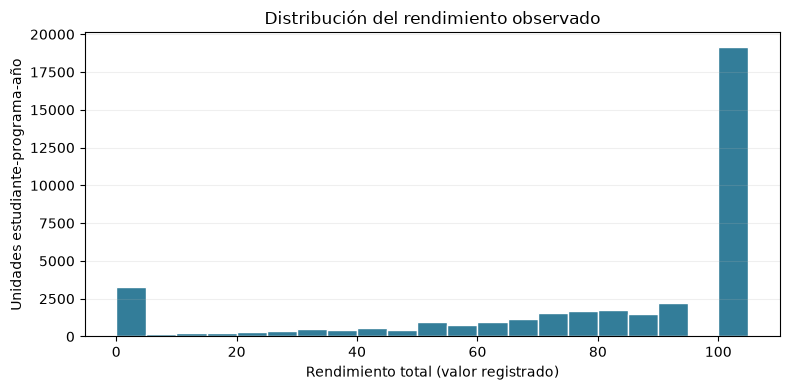

**Interpretación:** se dispone de rendimiento para **38,351** de **60,924** unidades. La mediana es **96.77** y la media **77.52**. El 50% central está entre **65.71** y **100.00**. Estos resultados corresponden a los valores disponibles, no a toda la población.

In [6]:
rendimiento = datos['rendimiento_total'].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(rendimiento, bins=np.arange(0, 106, 5), color='#337D99', edgecolor='white')
ax.set(title='Distribución del rendimiento observado',
       xlabel='Rendimiento total (valor registrado)', ylabel='Unidades estudiante-programa-año')
ax.grid(axis='y', alpha=0.2)
mostrar_figura(fig, '01_histograma_rendimiento.png')
display(Markdown(f'**Interpretación:** se dispone de rendimiento para **{len(rendimiento):,}** '
                 f'de **{len(datos):,}** unidades. La mediana es **{rendimiento.median():.2f}** '
                 f'y la media **{rendimiento.mean():.2f}**. El 50% central está entre '
                 f'**{rendimiento.quantile(.25):.2f}** y **{rendimiento.quantile(.75):.2f}**. '
                 'Estos resultados corresponden a los valores disponibles, no a toda la población.'))

### Figura 2. Boxplot de rendimiento
La caja representa el 50% central y la línea interior señala la mediana. Los puntos fuera de los bigotes se revisan con la regla IQR. Esta figura complementa el histograma y no modifica los datos.

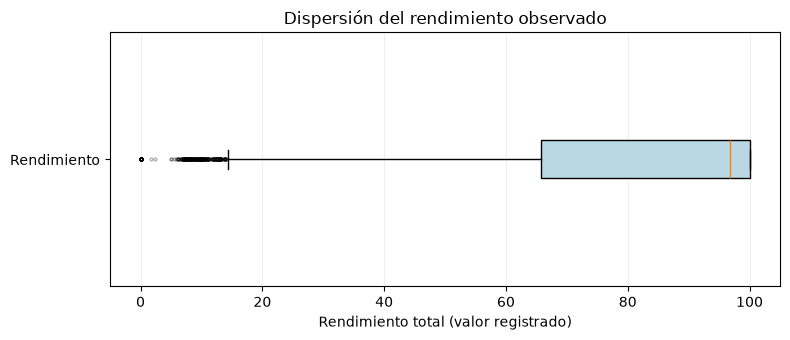

**Interpretación:** la mediana es **96.77**. Los límites IQR son **14.27** y **151.44**. Se señalan **3,640** extremos de **38,351** valores observados. Se conservan hasta comprobar su significado académico.

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot(datos['rendimiento_total'].dropna(), orientation='horizontal', patch_artist=True,
           boxprops={'facecolor': '#B9D8E3'}, flierprops={'markersize': 2, 'alpha': .3})
ax.set(title='Dispersión del rendimiento observado', xlabel='Rendimiento total (valor registrado)',
       yticks=[1], yticklabels=['Rendimiento'])
ax.grid(axis='x', alpha=.2)
mostrar_figura(fig, '02_boxplot_rendimiento.png')
f = extremos.loc['rendimiento_total']
display(Markdown(f'**Interpretación:** la mediana es **{datos["rendimiento_total"].median():.2f}**. '
                 f'Los límites IQR son **{f.limite_inferior:.2f}** y **{f.limite_superior:.2f}**. '
                 f'Se señalan **{int(f.n_extremos):,}** extremos de **{int(f.n_observados):,}** valores observados. '
                 'Se conservan hasta comprobar su significado académico.'))

### Figura 3. Histograma de créditos superados
Muestra cómo se distribuyen los valores de `cred_sup`. Permite identificar concentraciones y colas. El periodo exacto de los créditos debe confirmarse; no se supone que todos correspondan a un solo semestre o año.

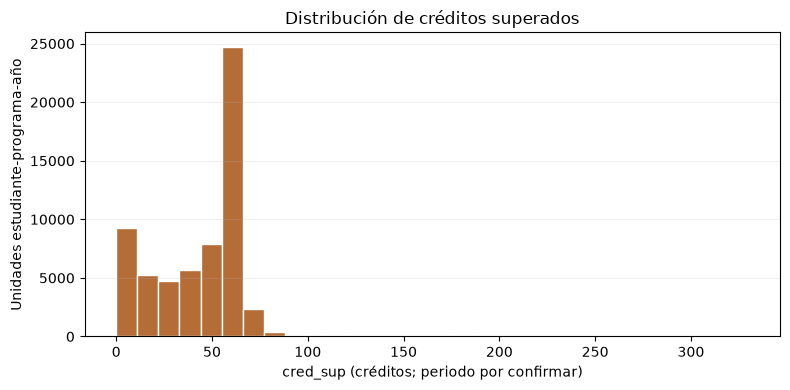

**Interpretación:** hay **60,924** valores disponibles. La mediana es **51.00**, la media **43.12** y la asimetría **0.99**. La diferencia entre media y mediana debe tenerse en cuenta al describir el valor típico; los créditos altos requieren revisar si corresponden a un periodo acumulado.

In [8]:
creditos = datos['cred_sup'].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(creditos, bins=30, color='#B56D37', edgecolor='white')
ax.set(title='Distribución de créditos superados', xlabel='cred_sup (créditos; periodo por confirmar)',
       ylabel='Unidades estudiante-programa-año')
ax.grid(axis='y', alpha=.2)
mostrar_figura(fig, '03_histograma_creditos.png')
display(Markdown(f'**Interpretación:** hay **{len(creditos):,}** valores disponibles. '
                 f'La mediana es **{creditos.median():.2f}**, la media **{creditos.mean():.2f}** '
                 f'y la asimetría **{creditos.skew():.2f}**. '
                 'La diferencia entre media y mediana debe tenerse en cuenta al describir el valor típico; '
                 'los créditos altos requieren revisar si corresponden a un periodo acumulado.'))

### Figura 4. Boxplot de créditos superados
**Qué muestra:** la mediana, el 50% central y los valores que se alejan de la distribución de `cred_sup`.

**Para qué sirve:** detectar posibles valores extremos para revisar. Se usa la regla IQR: valores fuera de Q1−1,5·IQR y Q3+1,5·IQR. No se eliminan sin verificar el periodo y las reglas académicas.

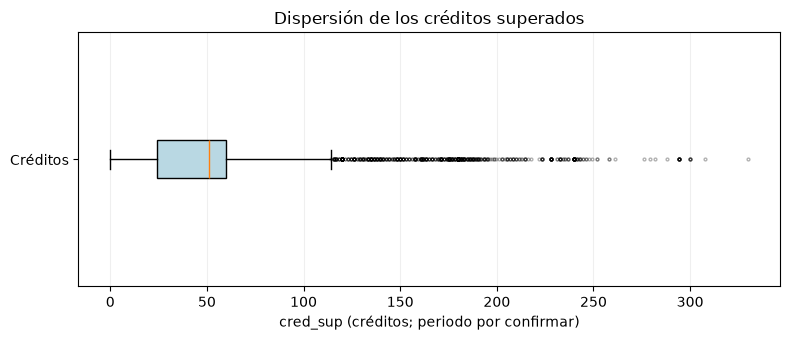

**Interpretación:** la mediana es **51.00**. Los límites IQR son **-30.00** y **114.00**; **552** de **60,924** valores quedan fuera. Se mantienen en el análisis porque no hay evidencia suficiente para tratarlos como errores.

In [9]:
creditos = datos['cred_sup'].dropna()
q1, q3 = creditos.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_extremos = int(((creditos < limite_inferior) | (creditos > limite_superior)).sum())
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot(creditos, orientation="horizontal", patch_artist=True,
           boxprops={'facecolor': '#B9D8E3'}, flierprops={'markersize': 2, 'alpha': .3})
ax.set(title='Dispersión de los créditos superados',
       xlabel='cred_sup (créditos; periodo por confirmar)', yticks=[1], yticklabels=['Créditos'])
ax.grid(axis='x', alpha=.2)
mostrar_figura(fig, '04_boxplot_creditos.png')
display(Markdown(f'**Interpretación:** la mediana es **{creditos.median():.2f}**. '
                 f'Los límites IQR son **{limite_inferior:.2f}** y **{limite_superior:.2f}**; '
                 f'**{n_extremos:,}** de **{len(creditos):,}** valores quedan fuera. '
                 'Se mantienen en el análisis porque no hay evidencia suficiente para tratarlos como errores.'))

## 4. Análisis bivariado y multivariado
Se examinan pares y conjuntos de variables: correlaciones clasificadas, dispersión, mapa de calor y cruces con el campo objetivo registrado.

### Función de clasificación
Pearson mide asociación lineal de −1 a 1. El signo indica dirección y la magnitud indica fuerza; no demuestra causalidad. Se aplica la escala orientativa de sesión 5: |r| <0,1 sin relación apreciable; [0,1;0,3) débil; [0,3;0,5) moderada; [0,5;0,7] fuerte; >0,7 muy fuerte. Se informan pares válidos y casos no definidos. Tres pares es un mínimo operativo, no una garantía estadística.

In [10]:
def clasificar_correlacion(r, n_pares):
    if n_pares < 3 or not np.isfinite(r) or abs(r) > 1:
        return 'No definida'
    magnitud = abs(r)
    if magnitud < .1:
        fuerza = 'Sin relación lineal apreciable'
    elif magnitud < .3:
        fuerza = 'Débil'
    elif magnitud < .5:
        fuerza = 'Moderada'
    elif magnitud <= .7:
        fuerza = 'Fuerte'
    else:
        fuerza = 'Muy fuerte'
    direccion = 'positiva' if r > 0 else ('negativa' if r < 0 else 'nula')
    return fuerza + ', dirección ' + direccion

filas = []
for i, x in enumerate(variables):
    for y in variables[i+1:]:
        pares = datos[[x, y]].dropna()
        r = pares[x].corr(pares[y]) if len(pares) >= 3 and pares[x].nunique() > 1 and pares[y].nunique() > 1 else np.nan
        filas.append({'variable_1': x, 'variable_2': y, 'pares_validos': len(pares),
                      'r': r, 'clasificacion': clasificar_correlacion(r, len(pares))})
correlaciones = pd.DataFrame(filas)
display(correlaciones.round(4))
correlaciones.to_csv(SALIDA / 'correlaciones.csv', index=False)
# Comprobaciones de la función; no representan correlaciones del proyecto.
assert clasificar_correlacion(.7, 10).startswith('Fuerte')
assert clasificar_correlacion(-.8, 10).startswith('Muy fuerte')
assert clasificar_correlacion(np.nan, 10) == 'No definida'

,variable_1,variable_2,pares_validos,r,clasificacion
0,rendimiento_total,cred_sup,38351,0.6651,"Fuerte, dirección positiva"
1,rendimiento_total,cred_mat_total,38351,0.2118,"Débil, dirección positiva"
2,rendimiento_total,rend_total_ultimo,28510,0.4966,"Moderada, dirección positiva"
3,cred_sup,cred_mat_total,60924,0.5106,"Fuerte, dirección positiva"
4,cred_sup,rend_total_ultimo,43770,0.5602,"Fuerte, dirección positiva"
5,cred_mat_total,rend_total_ultimo,43770,0.3525,"Moderada, dirección positiva"


### Figura 5. Dispersión: créditos y rendimiento
**Qué muestra:** cada punto relaciona créditos y rendimiento de una unidad estudiante-programa-año.

**Para qué sirve:** observar la forma de la relación, la concentración y los posibles grupos. Se dibuja una muestra de hasta 5.000 puntos con semilla fija; la correlación se calcula con **todos** los pares disponibles. No se añade una recta para sugerir una relación causal.

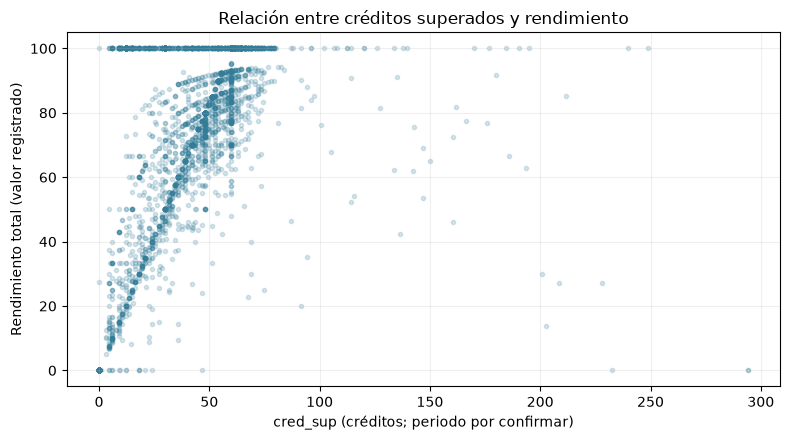

**Interpretación:** r = **0.665**, con **38,351** pares: **Fuerte, dirección positiva**. Los valores tienden a aumentar juntos. La relación puede depender de cómo se calculan las variables; no demuestra que aumentar los créditos cause mejor rendimiento ni menor abandono.

In [11]:
pares = datos[['cred_sup', 'rendimiento_total']].dropna()
muestra = pares.sample(n=min(5000, len(pares)), random_state=42)
r_creditos = pares['cred_sup'].corr(pares['rendimiento_total'])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(muestra['cred_sup'], muestra['rendimiento_total'], s=9, alpha=.2, color='#337D99')
ax.set(title='Relación entre créditos superados y rendimiento',
       xlabel='cred_sup (créditos; periodo por confirmar)', ylabel='Rendimiento total (valor registrado)')
ax.grid(alpha=.2)
mostrar_figura(fig, '05_dispersion_creditos_rendimiento.png')
display(Markdown(f'**Interpretación:** r = **{r_creditos:.3f}**, con **{len(pares):,}** pares: '
                 f'**{clasificar_correlacion(r_creditos, len(pares))}**. '
                 'Los valores tienden a aumentar juntos. La relación puede depender de cómo se calculan '
                 'las variables; no demuestra que aumentar los créditos cause mejor rendimiento ni menor abandono.'))

### Figura 6. Mapa de calor de correlaciones
**Qué muestra:** las correlaciones entre las cuatro variables numéricas en una sola figura. Los tonos rojos indican relación positiva y los azules negativa; la escala está fijada entre −1 y 1.

**Para qué sirve:** comparar relaciones y elegir cruces para investigar. La diagonal vale 1 porque compara una variable consigo misma y no se toma como hallazgo. Cada celda incluye el número de pares observados; puede variar por los faltantes.

Se excluyen identificadores y códigos nominales. No se interpreta A/B como números, porque todavía falta confirmar qué código significa abandono.

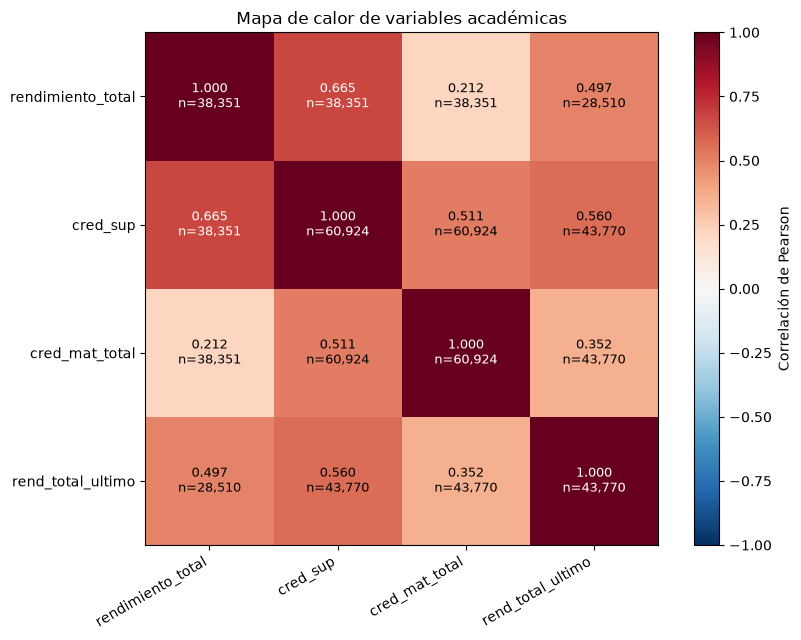

**Conclusión del mapa:** rendimiento y créditos superados presentan una relación **Fuerte, dirección positiva** (r = **0.665**). Rendimiento total y el campo `rend_total_ultimo` tienen r = **0.497**, clasificada como **Moderada, dirección positiva**. Se propone revisar estos cruces, sus fórmulas y periodos antes de usarlos como posibles indicadores. Las relaciones observadas no son evidencia causal sobre deserción.

In [12]:
matriz = datos[variables].corr(min_periods=3)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
imagen = ax.imshow(matriz, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(variables)), variables, rotation=30, ha='right')
ax.set_yticks(range(len(variables)), variables)
for i, x in enumerate(variables):
    for j, y in enumerate(variables):
        r = matriz.loc[x, y]
        cantidad = int(datos[x].notna().sum()) if x == y else int(datos[[x, y]].notna().all(axis=1).sum())
        etiqueta = f'{r:.3f}\nn={cantidad:,}' if np.isfinite(r) else 'No definida'
        ax.text(j, i, etiqueta, ha='center', va='center', fontsize=9,
                color='white' if np.isfinite(r) and abs(r) > .6 else 'black')
ax.set_title('Mapa de calor de variables académicas')
fig.colorbar(imagen, ax=ax, label='Correlación de Pearson')
mostrar_figura(fig, '06_mapa_calor.png')
f_previo = correlaciones.loc[(correlaciones.variable_1 == 'rendimiento_total') &
                             (correlaciones.variable_2 == 'rend_total_ultimo')].iloc[0]
display(Markdown(f'**Conclusión del mapa:** rendimiento y créditos superados presentan una relación '
                 f'**{clasificar_correlacion(r_creditos, len(pares))}** (r = **{r_creditos:.3f}**). '
                 f'Rendimiento total y el campo `rend_total_ultimo` tienen r = **{f_previo.r:.3f}**, '
                 f'clasificada como **{f_previo.clasificacion}**. '
                 'Se propone revisar estos cruces, sus fórmulas y periodos antes de usarlos como posibles indicadores. '
                 'Las relaciones observadas no son evidencia causal sobre deserción.'))

### Figura 7. Cruces con el estado registrado
Se compara `abandono_hash` con la dedicación registrada y con el año del archivo. Se calculan conteos y porcentajes dentro de cada grupo con su denominador.

**Limitación de interpretación:** A y B son códigos sin definición confirmada; se habla de “porcentaje de código A”, no de tasa de deserción. Tampoco se expanden TC/TP sin confirmar el catálogo. Estos cruces permiten describir la etiqueta y cumplir la exploración del campo objetivo, pero su traducción a abandono requiere el diccionario.

La figura muestra porcentajes por dedicación. El cruce por año queda en tabla. Los tamaños desiguales y la mezcla de programas/años pueden influir en las diferencias.

Unidades excluidas de los cruces por estado ausente o conflictivo: 0


abandono_hash,A,B,total
dedicacion,,,
TC,3952,55259,59211
TP,342,1371,1713


abandono_hash,A,B
dedicacion,,
TC,6.67,93.33
TP,19.96,80.04


abandono_hash,A,B,total
cohorte,,,
2018,1436,18797,20233
2021,1364,18900,20264
2022,1494,18933,20427


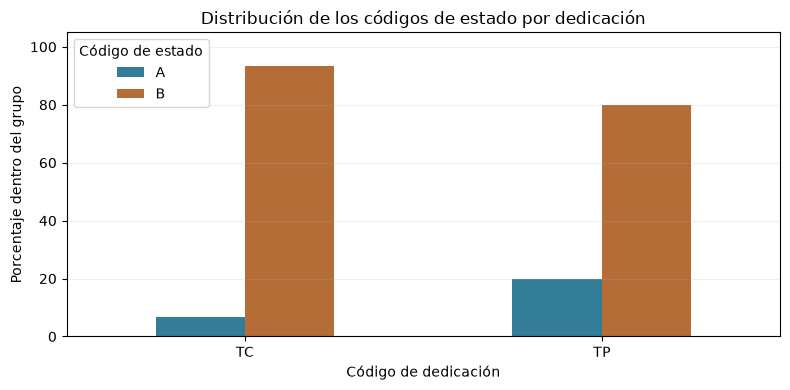

**Interpretación:** TC: 6.67% de código A (n=59,211); TP: 19.96% de código A (n=1,713). Las proporciones difieren entre grupos. Se recomienda confirmar los códigos y revisar la mezcla de años/programas antes de atribuir la diferencia a dedicación o denominarla deserción.

In [13]:
estados_validos = datos.loc[datos['abandono_hash'].isin(['A', 'B'])].copy()
excluidos_estado = len(datos) - len(estados_validos)
print('Unidades excluidas de los cruces por estado ausente o conflictivo:', excluidos_estado)
conteos = pd.crosstab(estados_validos['dedicacion'].fillna('SIN DATO'), estados_validos['abandono_hash'])
porcentajes = conteos.div(conteos.sum(axis=1), axis=0) * 100
display(conteos.assign(total=conteos.sum(axis=1)))
display(porcentajes.round(2))
por_anio = pd.crosstab(estados_validos['cohorte'], estados_validos['abandono_hash'])
display(por_anio.assign(total=por_anio.sum(axis=1)))
conteos.to_csv(SALIDA / 'cruce_estado_dedicacion_conteos.csv')
porcentajes.to_csv(SALIDA / 'cruce_estado_dedicacion_porcentajes.csv')
por_anio.to_csv(SALIDA / 'cruce_estado_anio.csv')
fig, ax = plt.subplots(figsize=(8, 4))
porcentajes.plot.bar(ax=ax, color=['#337D99', '#B56D37'], rot=0)
ax.set(title='Distribución de los códigos de estado por dedicación', xlabel='Código de dedicación',
       ylabel='Porcentaje dentro del grupo', ylim=(0, 105))
ax.legend(title='Código de estado'); ax.grid(axis='y', alpha=.2)
mostrar_figura(fig, '07_cruce_estado_dedicacion.png')
lectura = '; '.join(f'{k}: {v:.2f}% de código A (n={int(conteos.loc[k].sum()):,})'
                    for k, v in porcentajes['A'].items())
display(Markdown('**Interpretación:** ' + lectura + '. Las proporciones difieren entre grupos. '
                 'Se recomienda confirmar los códigos y revisar la mezcla de años/programas antes de atribuir '
                 'la diferencia a dedicación o denominarla deserción.'))

## 5. Hallazgos y recomendaciones
Cada hallazgo relaciona un resultado verificable con una evidencia y una acción sugerida. No se promete que una intervención reduzca abandono sin evaluarla. Se incluyen cuatro hallazgos para cubrir calidad, asociaciones y segmentación.

In [14]:
faltantes_2018 = int(calidad_anio.loc[2018, 'faltantes'])
hallazgos = pd.DataFrame([
    {'Hallazgo': 'No hay rendimiento original disponible para 2018.',
     'Evidencia': f'{faltantes_2018:,} faltantes de {int(calidad_anio.loc[2018, "filas"]):,} matrículas de ese año; tabla de revisión inicial.',
     'Acción sugerida': 'Solicitar documentación de disponibilidad y analizar por año; no presentar el relleno como rendimiento medido.'},
    {'Hallazgo': 'Rendimiento y créditos presentan asociación ' + clasificar_correlacion(r_creditos, len(pares)).lower() + '.',
     'Evidencia': f'r={r_creditos:.3f}; {len(pares):,} pares; figuras 5 y 6.',
     'Acción sugerida': 'Revisar si comparten fórmula o periodo y evaluar redundancia antes de proponer indicadores de acompañamiento.'},
    {'Hallazgo': 'El rendimiento total se asocia con el campo de rendimiento previo: ' + f_previo.clasificacion.lower() + '.',
     'Evidencia': f'r={f_previo.r:.3f}; {int(f_previo.pares_validos):,} pares; figura 6.',
     'Acción sugerida': 'Confirmar qué periodo representa el campo previo y estudiar la relación por año antes de usarla para alertas.'}
])
hallazgos = pd.concat([hallazgos, pd.DataFrame([{
    'Hallazgo': 'La proporción del código A difiere entre las categorías de dedicación registradas.',
    'Evidencia': lectura + '; tabla cruzada y figura 7.',
    'Acción sugerida': 'Confirmar el mapa de A/B y los códigos de dedicación; después contrastar la diferencia por año y programa antes de sugerir acompañamiento específico.'
}])], ignore_index=True)
for i, fila in hallazgos.iterrows():
    display(Markdown(f'### Hallazgo {i+1}\n{fila["Hallazgo"]}\n\n'
                     f'**Evidencia:** {fila["Evidencia"]}\n\n'
                     f'**Acción sugerida:** {fila["Acción sugerida"]}'))
hallazgos.to_csv(SALIDA / 'hallazgos.csv', index=False)

### Hallazgo 1
No hay rendimiento original disponible para 2018.

**Evidencia:** 152,446 faltantes de 152,446 matrículas de ese año; tabla de revisión inicial.

**Acción sugerida:** Solicitar documentación de disponibilidad y analizar por año; no presentar el relleno como rendimiento medido.

### Hallazgo 2
Rendimiento y créditos presentan asociación fuerte, dirección positiva.

**Evidencia:** r=0.665; 38,351 pares; figuras 5 y 6.

**Acción sugerida:** Revisar si comparten fórmula o periodo y evaluar redundancia antes de proponer indicadores de acompañamiento.

### Hallazgo 3
El rendimiento total se asocia con el campo de rendimiento previo: moderada, dirección positiva.

**Evidencia:** r=0.497; 28,510 pares; figura 6.

**Acción sugerida:** Confirmar qué periodo representa el campo previo y estudiar la relación por año antes de usarla para alertas.

### Hallazgo 4
La proporción del código A difiere entre las categorías de dedicación registradas.

**Evidencia:** TC: 6.67% de código A (n=59,211); TP: 19.96% de código A (n=1,713); tabla cruzada y figura 7.

**Acción sugerida:** Confirmar el mapa de A/B y los códigos de dedicación; después contrastar la diferencia por año y programa antes de sugerir acompañamiento específico.

### Conclusiones y limitaciones
El análisis documenta la disponibilidad del rendimiento, cuantifica extremos y muestra relaciones académicas y diferencias entre códigos de estado. La ausencia de rendimiento en 2018 demuestra que la preparación debe justificarse antes de interpretar los gráficos.

Las asociaciones orientan preguntas para el siguiente avance, pero no identifican causas ni constituyen un modelo predictivo validado. Deben confirmarse el significado de A/B, el horizonte de abandono y las fórmulas y periodos de las variables.

La población es española; las unidades analíticas pueden repetir personas entre años/programas. Se conservan ausencias justificadas y cada correlación usa sus pares disponibles. No se calculan pruebas causales ni precisión predictiva.

La sección de cruces está calculada, pero su interpretación en términos de deserción permanece pendiente del diccionario autorizado. Esta limitación debe explicarse en la revisión, no ocultarse.

## 6. Anexos y reproducibilidad
El código completo ejecutado de este notebook constituye el anexo reproducible. Se exportan tablas, siete figuras, el CSV de la vista analítica, un diccionario que distingue definiciones provisionales y una bitácora.

El CSV corresponde a la vista estudiante-programa-año con faltantes explícitos y justificados; no se renombra un original como “limpio” ni se ocultan ausencias. El diccionario cubre todas sus columnas; no pretende definir las 386 columnas de la base original.

Para repetir: colocar la base junto al notebook, seleccionar Python con pandas/numpy/matplotlib y ejecutar todas las celdas. La comprobación completa de duplicados puede tardar varios minutos. Guardar el notebook con sus salidas al terminar.

In [15]:
descripciones = {
    'dni_hash': ('Identificador anonimizado de persona', 'Identificador', 'Clave; normalizar espacios/mayúsculas'),
    'tit_hash': ('Identificador anonimizado de programa/titulación', 'Categoría; catálogo pendiente', 'Clave; normalizar espacios/mayúsculas'),
    'cohorte': ('Año del archivo añadido en la carga, no necesariamente año de ingreso', 'Año: 2018, 2021, 2022', 'Clave de agrupación'),
    'rendimiento_total': ('Rendimiento total registrado; fórmula oficial pendiente', 'Valor registrado; unidad oficial pendiente', 'Mediana del grupo; preservar ausencias'),
    'cred_sup': ('Créditos superados; periodo por confirmar', 'Créditos; anual/acumulado pendiente', 'Mediana del grupo; preservar ausencias'),
    'cred_mat_total': ('Créditos matriculados totales; periodo por confirmar', 'Créditos; periodo pendiente', 'Mediana del grupo; preservar ausencias'),
    'rend_total_ultimo': ('Campo de rendimiento previo/último; cronología pendiente', 'Valor registrado; unidad oficial pendiente', 'Mediana del grupo; preservar ausencias'),
    'abandono_hash': ('Código del estado objetivo; significado de A/B pendiente', 'Categoría nominal', 'Consistencia dentro del grupo; marcar conflictos'),
    'dedicacion': ('Código de dedicación; catálogo TC/TP pendiente', 'Categoría nominal', 'Consistencia dentro del grupo; marcar conflictos'),
    'n_matriculas': ('Número de filas originales agrupadas', 'Matrículas en asignaturas', 'Conteo del grupo')}
filas_diccionario = []
for col in datos:
    descripcion, unidad, tratamiento = descripciones[col]
    s = datos[col]
    observado = f'[{s.min()}, {s.max()}]' if pd.api.types.is_numeric_dtype(s) else ', '.join(map(str, s.dropna().unique()))
    filas_diccionario.append({'columna': col, 'tipo': str(s.dtype), 'descripcion': descripcion,
                              'unidad_y_dominio': unidad, 'valores_observados_no_rango_oficial': observado,
                              'faltantes': int(s.isna().sum()), 'tratamiento': tratamiento})
diccionario = pd.DataFrame(filas_diccionario)
display(diccionario)
datos.to_csv(SALIDA / 'vista_analitica_documentada.csv', index=False)
diccionario.to_csv(SALIDA / 'diccionario_vista_analitica.csv', index=False)
reabierto = pd.read_csv(SALIDA / 'vista_analitica_documentada.csv')
assert reabierto.shape == datos.shape
assert not reabierto.duplicated(claves).any()
assert set(diccionario['columna']) == set(datos.columns)
assert len(list(SALIDA.glob('0[1-7]_*.png'))) == 7
print('Verificado: siete figuras, clave analítica única y diccionario de todas las columnas exportadas.')
print('Resultados guardados en:', SALIDA.resolve())
print('La base no se modificó. No se realizaron operaciones Git.')

,columna,tipo,descripcion,unidad_y_dominio,valores_observados_no_rango_oficial,faltantes,tratamiento
0,dni_hash,string,Identificador anonimizado de persona,Identificador,"0002CCC8623E, 0003110CDAFF, 0004CE050425, 0005...",0,Clave; normalizar espacios/mayúsculas
1,tit_hash,string,Identificador anonimizado de programa/titulación,Categoría; catálogo pendiente,"EC2E990B934D, 740C59B88403, 1D0EBEA552EB, BB66...",0,Clave; normalizar espacios/mayúsculas
2,cohorte,int64,"Año del archivo añadido en la carga, no necesa...","Año: 2018, 2021, 2022","[2018, 2022]",0,Clave de agrupación
3,rendimiento_total,float64,Rendimiento total registrado; fórmula oficial ...,Valor registrado; unidad oficial pendiente,"[0.0, 100.0]",22573,Mediana del grupo; preservar ausencias
4,cred_sup,float64,Créditos superados; periodo por confirmar,Créditos; anual/acumulado pendiente,"[0.0, 330.0]",0,Mediana del grupo; preservar ausencias
5,cred_mat_total,float64,Créditos matriculados totales; periodo por con...,Créditos; periodo pendiente,"[0.0, 306.0]",0,Mediana del grupo; preservar ausencias
6,rend_total_ultimo,float64,Campo de rendimiento previo/último; cronología...,Valor registrado; unidad oficial pendiente,"[0.0, 100.0]",17154,Mediana del grupo; preservar ausencias
7,abandono_hash,string,Código del estado objetivo; significado de A/B...,Categoría nominal,"B, A",0,Consistencia dentro del grupo; marcar conflictos
8,dedicacion,string,Código de dedicación; catálogo TC/TP pendiente,Categoría nominal,"TC, TP",0,Consistencia dentro del grupo; marcar conflictos
9,n_matriculas,int64,Número de filas originales agrupadas,Matrículas en asignaturas,"[1, 47]",0,Conteo del grupo


Verificado: siete figuras, clave analítica única y diccionario de todas las columnas exportadas.
Resultados guardados en: /Users/usuario/Documents/Codex/2026-10-18/referenced-chatgpt-conversation-this-is-an/outputs/resultados_entrega
La base no se modificó. No se realizaron operaciones Git.


### Referencias
- StudentDropoutDataset (2025). [Zenodo, DOI 10.5281/zenodo.17239943](https://doi.org/10.5281/zenodo.17239943), CC BY 4.0.
- Material del docente: sesión 5, Análisis Exploratorio de Datos, pp. 8 y 27–31 (correlaciones, estructura del informe y hallazgos evidencia–acción).
- Material del docente: sesión 6, pp. 11–13 (calidad, diccionario y cuaderno ejecutado).
- [Repositorio del equipo](https://github.com/daiz2018/mineria_de_datos), scripts de preparación revisados en `d0208f0e422e1c3d69d4b499037c361273022033`.

Trabajo elaborado con apoyo de IA; los integrantes deben revisar decisiones y resultados, comprender su interpretación y cumplir las condiciones de uso de IA de la asignatura. Este cuaderno no resuelve el examen individual StreamAndes.